# Figure 7c. PPI network of microglial trans-eProgram 27

STRING (v12.5, *Homo sapiens*, combined score >= 0.4) network among the 87 genes of microglial Hotspot *trans*-eProgram 27; red edges are pairs that also have physical-interaction evidence, grey edges functional association only. Only genes with at least one edge are drawn, plus *MS4A4E* (red). *MS4A4E*'s rank is its position when program genes are ordered by the marginal *trans*-association p-value of the KNOP1-locus lead variant (chr16:19696874:A:G) with covariate-adjusted microglia expression (genes on chr16 set to p = 1). The node layout is a seeded Fruchterman-Reingold layout, not the hand-arranged published layout.

Input: `data/Figure_7c_Mic_program27_PPI.rds`

In [1]:
library(ggplot2)
library(ggrepel)
ppi <- readRDS("data/Figure_7c_Mic_program27_PPI.rds")
## STRING v12.5, combined score >= 0.4; nodes = genes with >= 1 edge plus the focal gene
c(n_query_genes = ppi$n_query, n_nodes = nrow(ppi$nodes), n_edges = nrow(ppi$edges))
table(ppi$edges$type)
head(ppi$edges)
## trans-association ranking of program genes for the lead variant chr16:19696874:A:G
head(ppi$module_ranking, 8)

n_query_genes       n_nodes       n_edges 
           87            49            68


Functional association only     Physical-proximity link 
                         44                          24 

,gene_a,gene_b,functional_score,physical_score,type,x,y,xend,yend
,<chr>,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,CMTM6,CMTM7,0.965,NA,Functional association only,-2.81025019,5.813457,-2.0095010,6.1654675
2,RIN3,USP9X,0.456,0.456,Physical-proximity link,0.04495389,2.460266,0.8615131,-0.2738204
3,RIN3,APOE,0.466,NA,Functional association only,0.04495389,2.460266,0.1579258,1.6702264
4,RIN3,ABI1,0.469,0.456,Physical-proximity link,0.04495389,2.460266,0.1381257,4.5639534
5,RIN3,MS4A4E,0.496,NA,Functional association only,0.04495389,2.460266,-0.1992986,3.3810831
6,RIN3,MS4A6A,0.627,NA,Functional association only,0.04495389,2.460266,-0.8615378,3.0509236


,ensembl_id,gene,z,p_value,rank
,<chr>,<chr>,<dbl>,<dbl>,<int>
ENSG00000198900,ENSG00000198900,TOP1,3.049055,0.002295622,1
ENSG00000059728,ENSG00000059728,MXD1,2.620171,0.008788570,2
ENSG00000073417,ENSG00000073417,PDE8A,2.532075,0.011338969,3
ENSG00000214787,ENSG00000214787,MS4A4E,-2.457983,0.013971979,4
ENSG00000120690,ENSG00000120690,ELF1,2.412378,0.015848848,5
ENSG00000172578,ENSG00000172578,KLHL6,2.313740,0.020682002,6
ENSG00000145860,ENSG00000145860,RNF145,2.193969,0.028237606,7
ENSG00000125354,ENSG00000125354,SEPTIN6,2.187803,0.028683922,8


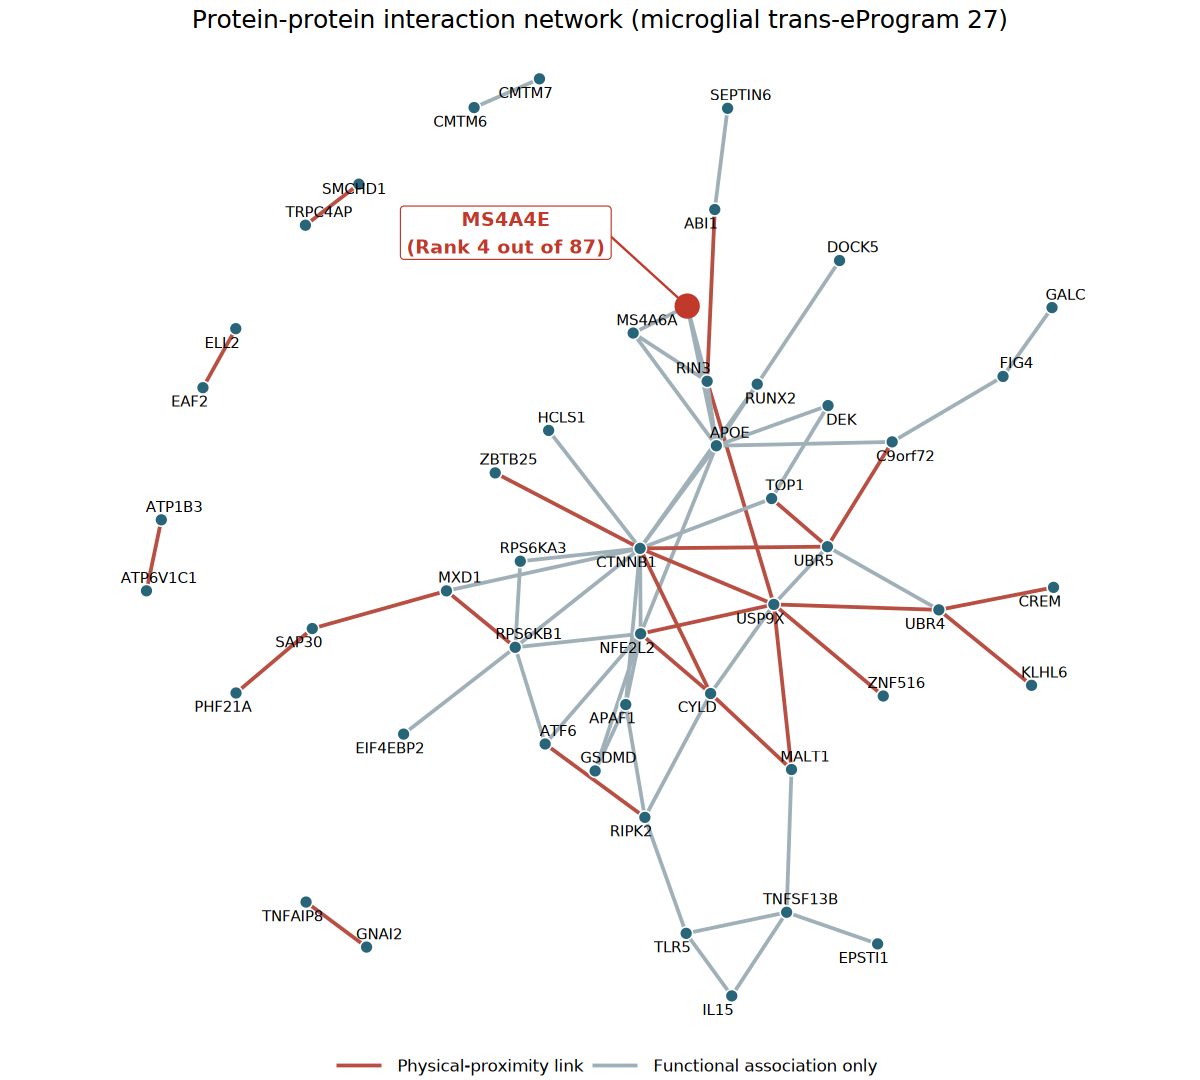

In [2]:
TITLE <- "Protein-protein interaction network (microglial trans-eProgram 27)"
r <- ppi$nodes[ppi$nodes$focal, "rank"]
FOCAL_LABEL <- sprintf("MS4A4E\n(Rank %d out of %d)", r, nrow(ppi$module_ranking))
NUDGE <- c(-0.2, 0.08)  # label offset as a fraction of the layout range
edges <- ppi$edges
nodes <- ppi$nodes
focal <- nodes[nodes$focal, ]
focal$label <- FOCAL_LABEL

p <- ggplot() +
  geom_segment(data = edges, aes(x, y, xend = xend, yend = yend, colour = type), linewidth = 0.8) +
  geom_point(data = nodes[!nodes$focal, ], aes(x, y), shape = 21, size = 3, fill = "#286579",
             colour = "white", stroke = 0.5) +
  geom_point(data = focal, aes(x, y), size = 6, colour = "#C0392B") +
  geom_text_repel(data = nodes[!nodes$focal, ], aes(x, y, label = gene), size = 3,
                  fontface = "italic", seed = 1, max.overlaps = Inf, min.segment.length = 0.3,
                  segment.colour = "grey70") +
  geom_label_repel(data = focal, aes(x, y, label = label), size = 4, fontface = "bold",
                   colour = "#C0392B", fill = "white", label.size = NA, seed = 1,
                   nudge_x = NUDGE[1] * diff(range(nodes$x)),
                   nudge_y = NUDGE[2] * diff(range(nodes$y)), box.padding = 0.6,
                   segment.colour = "#C0392B", max.overlaps = Inf) +
  scale_colour_manual(values = c("Physical-proximity link" = "#B94F43",
                                 "Functional association only" = "#A0B0B8"),
                      breaks = c("Physical-proximity link", "Functional association only"),
                      name = NULL) +
  labs(title = TITLE) +
  coord_fixed() +
  theme_void(base_size = 12) +
  theme(plot.title = element_text(hjust = 0.5), legend.position = "bottom",
        legend.key.width = grid::unit(12, "mm"))

options(repr.plot.width = 10, repr.plot.height = 9)
p